# Stokes flow with Taylor-Hood elements

Following the Stokes demo of the
[DOLFINx demos](https://docs.fenicsproject.org/dolfinx/main/python/demos.html) and the mixed
formulation chapters of the [FEniCSx tutorial](https://jsdokken.com/dolfinx-tutorial/).
Find velocity $u$ and pressure $p$ with

$$ -\Delta u + \nabla p = f, \qquad \nabla\cdot u = 0 \quad \text{in } \Omega = (0,1)^2, \qquad u = g \ \text{ on } \partial\Omega . $$

We use the Taylor-Hood pair, continuous $P_2$ velocity and continuous $P_1$ pressure, a
stable choice that satisfies the inf-sup condition.  Part (a) checks convergence rates
against a manufactured solution, part (b) is the lid driven cavity.

**Pressure level.**  With Dirichlet conditions on the whole boundary, $p$ appears only
through $\nabla p$, so it is determined up to an additive constant and the matrix is singular.
We fix the constant by requiring $\int_\Omega p\,dx = 0$ through a Lagrange multiplier $c$,
a single scalar unknown living in the `Real` space.

## Mixed formulation

A function in the mixed space $W = V \times Q \times R$ has the three components $(u, p, c)$.
The bilinear form is symmetric:

$$ a((u,p,c),(v,q,r)) = \int \nabla u : \nabla v - p\,\nabla\cdot v - q\,\nabla\cdot u + c\,q + r\,p \; dx . $$

In [1]:
from ngsufl import *


def stokes_problem(mesh, u_exact, p_exact):
    V = VectorFunctionSpace(mesh, "Lagrange", 2)
    Q = FunctionSpace(mesh, "Lagrange", 1)
    R = FunctionSpace(mesh, "Real", 0)
    W = V * Q * R

    (u, p, c), (v, q, r) = TrialFunctions(W), TestFunctions(W)
    f = -div(grad(u_exact)) + grad(p_exact)

    a = (inner(grad(u), grad(v)) - p * div(v) - q * div(u) + c * q + r * p) * dx
    L = inner(f, v) * dx

    bc = DirichletBC(W.sub(0), u_exact, "on_boundary")
    w = Function(W)
    solve(a == L, w, bc)
    uh, ph, _ = w.subfunctions
    return uh, ph

## (a) Manufactured solution and convergence

We derive a divergence free velocity from a stream function, $u = (\partial_y\psi, -\partial_x\psi)$
with $\psi = \sin(\pi x)\sin(\pi y)$, and take a pressure with zero mean.  The source term $f$ is
computed by UFL from these expressions, so nothing has to be differentiated by hand.
Velocity should converge with order 3 in $L^2$ and 2 in $H^1$, pressure with order 2 in $L^2$.

In [2]:
import numpy as np

hs, eu, eu1, ep = [], [], [], []
for n in (4, 8, 16, 32):
    mesh = UnitSquareMesh(n, n)
    x = SpatialCoordinate(mesh)
    psi = sin(pi * x[0]) * sin(pi * x[1])
    u_ex = as_vector((psi.dx(1), -psi.dx(0)))
    p_ex = cos(pi * x[0]) * sin(pi * x[1])

    uh, ph = stokes_problem(mesh, u_ex, p_ex)
    hs.append(1.0 / n)
    eu.append(errornorm(u_ex, uh))
    eu1.append(errornorm(u_ex, uh, "H1"))
    ep.append(errornorm(p_ex, ph))

rate = lambda e: np.log(e[:-1] / np.array(e[1:])) / np.log(2)
print("      h    |u-uh|_L2   |u-uh|_H1   |p-ph|_L2")
for h, a_, b_, c_ in zip(hs, eu, eu1, ep):
    print(f"{h:8.4f}  {a_:10.3e}  {b_:10.3e}  {c_:10.3e}")
print("rates u L2:", np.round(rate(eu), 2))
print("rates u H1:", np.round(rate(eu1), 2))
print("rates p L2:", np.round(rate(ep), 2))

      h    |u-uh|_L2   |u-uh|_H1   |p-ph|_L2
  0.2500   1.839e-02   5.779e-01   4.706e-02
  0.1250   2.391e-03   1.484e-01   7.332e-03
  0.0625   3.038e-04   3.741e-02   1.645e-03
  0.0312   3.816e-05   9.373e-03   4.035e-04
rates u L2: [2.94 2.98 2.99]
rates u H1: [1.96 1.99 2.  ]
rates p L2: [2.68 2.16 2.03]


The observed rates match the theory for the pair $P_2$-$P_1$.

## (b) Lid driven cavity

The lid moves with velocity $(1,0)$, the other three walls are at rest, and $f=0$.
The pressure is again fixed through its mean.  The two corners where lid and wall meet make the
pressure singular; a finer mesh near them would help, but the picture is already instructive.

In [3]:
mesh = UnitSquareMesh(32, 32)
V = VectorFunctionSpace(mesh, "Lagrange", 2)
Q = FunctionSpace(mesh, "Lagrange", 1)
R = FunctionSpace(mesh, "Real", 0)
W = V * Q * R

(u, p, c), (v, q, r) = TrialFunctions(W), TestFunctions(W)
a = (inner(grad(u), grad(v)) - p * div(v) - q * div(u) + c * q + r * p) * dx
L = inner(Constant((0.0, 0.0)), v) * dx

bcs = [DirichletBC(W.sub(0), (1.0, 0.0), "top"),
       DirichletBC(W.sub(0), (0.0, 0.0), "left|right|bottom")]
w = Function(W)
solve(a == L, w, bcs)
uh, ph, ch = w.subfunctions

print("mean pressure:", assemble(ph * dx))
print("multiplier value:", ch.array[0])
print("L2 norm of div u:", norm(div(uh)))

mean pressure: 6.938893903907228e-17
multiplier value: 2.0573767172001663e-17
L2 norm of div u: 0.6734709803760323


The velocity is only weakly divergence free: $\nabla\cdot u_h$ is orthogonal to $P_1$ but not zero.
Its norm is dominated by the two cells at the top corners, where the lid velocity jumps to zero
(away from the corners it is about 100 times smaller).  The multiplier is zero up to round-off, which says that the constraint was
compatible with the equations, as it must be.

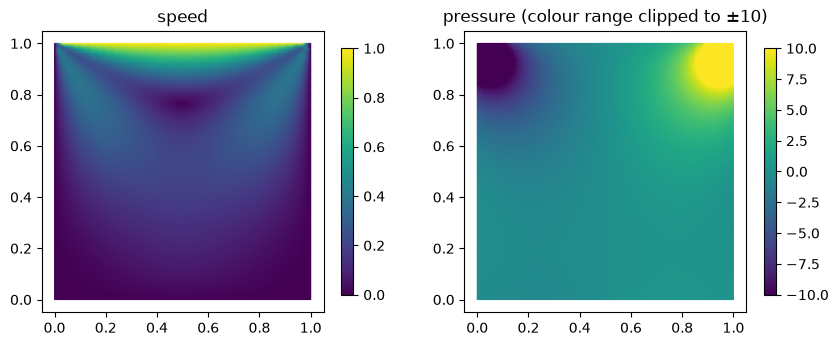

In [4]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
plot(sqrt(dot(uh, uh)), ax=axs[0])
axs[0].set_title("speed")
plot(ph, ax=axs[1], vmin=-10, vmax=10)
axs[1].set_title("pressure (colour range clipped to $\\pm 10$)");

The mesh was created by `UnitSquareMesh`, but the same code runs unchanged on any NGSolve
mesh, including curved ones built from OCC geometries (see the Navier-Stokes tutorial).